# 03 · FreeSurfer Brain Morphometry EDA
> *Cortical thickness, surface area, and subcortical volumes — derived from T1 MRI using FreeSurfer 7.*

## Background: What is FreeSurfer?

**FreeSurfer** is a software tool that automatically segments a T1 MRI into ~70 cortical regions and ~40 subcortical structures, then measures their size.

**Three types of measurements:**

| Measure | File | Unit | What it tells you |
|---------|------|------|-------------------|
| **Cortical Thickness (CTH)** | FS7_APARC_CTH | mm | How thick the cortex (grey matter outer layer) is in each region |
| **Surface Area (SA)** | FS7_APARC_SA | mm² | How large each cortical region is on the brain surface |
| **Subcortical Volume** | FS7_ASEG_VOL | mm³ | Volume of deep brain structures |

**Why this matters for PD:**
- **Putamen and caudate** (basal ganglia) shrink early in PD
- **Hippocampus and amygdala** shrink in PD with cognitive changes
- **Cortical thinning** appears in frontal/parietal regions in advanced PD
- These changes are subtle but detectable with enough participants

**Column naming convention:**
- `lh_` prefix = left hemisphere
- `rh_` prefix = right hemisphere
- Region names are from the Desikan-Killiany atlas (a standard brain parcellation)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.titlesize': 14,
                     'axes.labelsize': 12, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'figure.dpi': 120})
DATA_DIR = Path('../Imaging')
print(f'Data directory: {DATA_DIR.resolve()}')

Data directory: /Users/asadriaz/Desktop/PPMI Imaging/Imaging


In [2]:
VISIT_ORDER = ['SC', 'BL', 'V04', 'V06', 'V08', 'V10', 'V12', 'V14', 'V16', 'PW']
VISIT_LABELS = {'SC': 'Screening', 'BL': 'Baseline', 'PW': 'Withdrawal',
                'V04': 'Yr 1', 'V06': 'Yr 2', 'V08': 'Yr 3',
                'V10': 'Yr 4', 'V12': 'Yr 5', 'V14': 'Yr 6', 'V16': 'Yr 7'}
def ordered_visits(series):
    present = series.dropna().unique().tolist()
    ordered = [v for v in VISIT_ORDER if v in present]
    return ordered + sorted([v for v in present if v not in VISIT_ORDER])

## Load Data Files

In [3]:
cth  = pd.read_csv(DATA_DIR / 'FS7_APARC_CTH_12Nov2026.csv')
sa   = pd.read_csv(DATA_DIR / 'FS7_APARC_SA_12Nov2026.csv')
aseg = pd.read_csv(DATA_DIR / 'FS7_ASEG_VOL_12Nov2026.csv')
for name, df in [('Cortical Thickness (CTH)', cth), ('Surface Area (SA)', sa),
                 ('Subcortical Volumes (ASEG)', aseg)]:
    print(f'{name:35s}: {len(df):>5,} rows | {df["PATNO"].nunique()} participants | {df.shape[1]} columns')

Cortical Thickness (CTH)           : 1,716 rows | 1716 participants | 72 columns
Surface Area (SA)                  : 1,716 rows | 1716 participants | 72 columns
Subcortical Volumes (ASEG)         : 1,713 rows | 1713 participants | 66 columns


## Column Reference

### Cortical Thickness / Surface Area (APARC)
Columns follow the pattern `{hemisphere}_{region}`:
- `lh_` = left hemisphere, `rh_` = right hemisphere
- `lh_MeanThickness` / `rh_WhiteSurfArea` = whole-hemisphere summary
- 34 cortical regions per hemisphere (see list below)

**Key cortical regions in PD research:**
| Region | Why it matters |
|--------|---------------|
| `precentral` | Motor cortex — controls voluntary movement |
| `postcentral` | Somatosensory cortex |
| `superiorfrontal`, `rostralmiddlefrontal` | Frontal executive function |
| `entorhinal`, `parahippocampal` | Memory/hippocampal circuit |
| `insula` | Autonomic regulation, emotion |
| `transversetemporal` | Primary auditory cortex |

### Subcortical Volumes (ASEG)
**PD-critical structures:**
| Column | Structure | PD Relevance |
|--------|-----------|-------------|
| `Left-Caudate`, `Right-Caudate` | Caudate nucleus | Dopamine target; shrinks in PD |
| `Left-Putamen`, `Right-Putamen` | Putamen | Most-affected basal ganglia in PD |
| `Left-Hippocampus`, `Right-Hippocampus` | Hippocampus | Memory; affected in PD-dementia |
| `Left-Amygdala`, `Right-Amygdala` | Amygdala | Emotion/autonomic; affected in PD |
| `Brain-Stem` | Brainstem | Contains SN; affected early |
| `Left-Thalamus`, `Right-Thalamus` | Thalamus | Relay station |
| `EstimatedTotalIntraCranialVol` | eTIV | Head size — used for normalization |
| `BrainSegVol` | Total brain segment volume | Overall brain size |
| `TotalGrayVol` | Total grey matter | Overall atrophy measure |

## 1 · Mean Cortical Thickness by Region

Average cortical thickness across all participants for each region. The cortex is typically 2–4 mm thick.

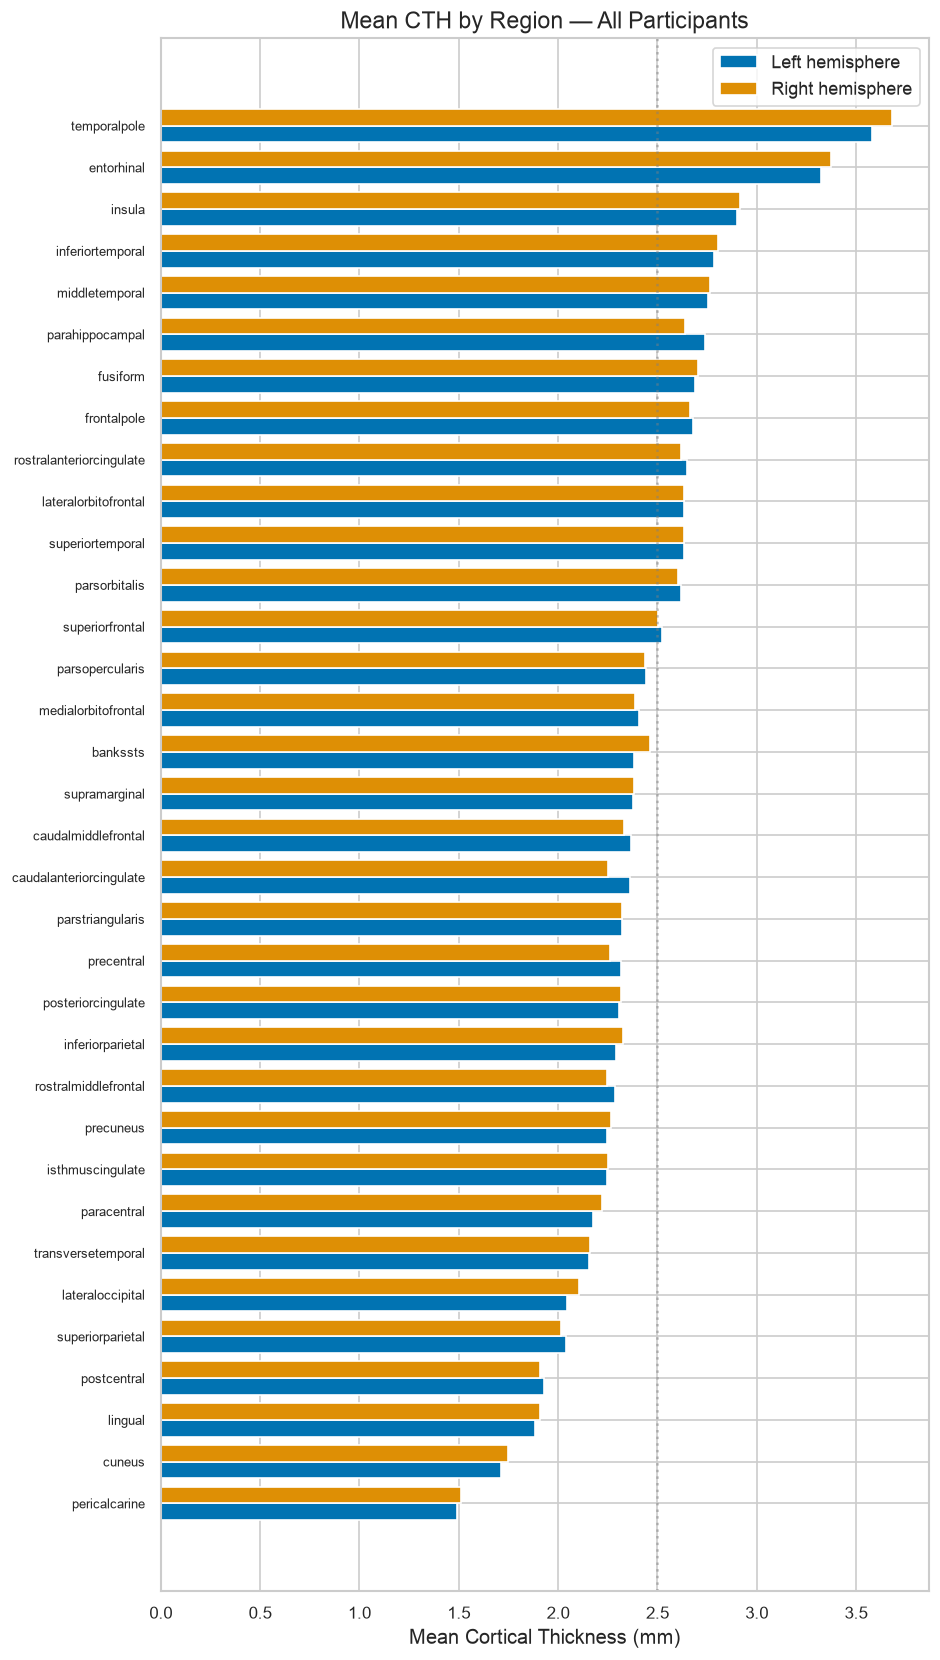

In [4]:
cth_cols = [c for c in cth.columns if c.startswith('lh_') and c != 'lh_MeanThickness']
rh_cols  = [c.replace('lh_','rh_') for c in cth_cols if c.replace('lh_','rh_') in cth.columns]

lh_means = cth[cth_cols].mean().rename(lambda c: c.replace('lh_',''))
rh_means = cth[rh_cols].mean().rename(lambda c: c.replace('rh_',''))
both = pd.DataFrame({'Left': lh_means, 'Right': rh_means}).sort_values('Left')

fig, ax = plt.subplots(figsize=(8, 14))
y = range(len(both))
ax.barh([i-0.2 for i in y], both['Left'], height=0.4,
        color=sns.color_palette('colorblind')[0], label='Left hemisphere')
ax.barh([i+0.2 for i in y], both['Right'], height=0.4,
        color=sns.color_palette('colorblind')[1], label='Right hemisphere')
ax.set_yticks(list(y)); ax.set_yticklabels(both.index, fontsize=8)
ax.set_xlabel('Mean Cortical Thickness (mm)'); ax.set_title('Mean CTH by Region — All Participants')
ax.legend(); ax.axvline(2.5, color='grey', linestyle=':', alpha=0.5)
plt.tight_layout(); plt.show()

## 2 · Left vs Right Hemisphere Thickness Asymmetry

Is the brain symmetric? Each dot is one participant. Points off the diagonal indicate hemispheric asymmetry.

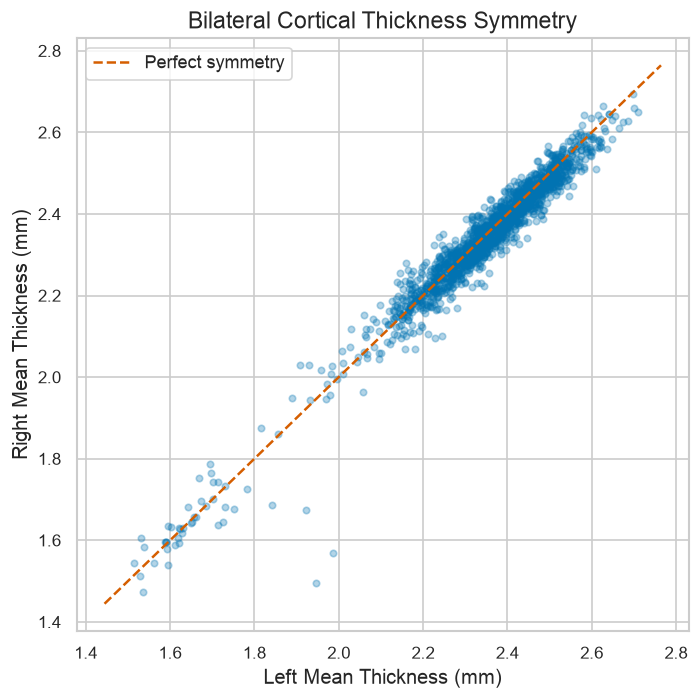

Mean L-R asymmetry: 0.0060 mm | Std: 0.0370 mm


In [5]:
if 'lh_MeanThickness' in cth.columns and 'rh_MeanThickness' in cth.columns:
    sub = cth[['lh_MeanThickness','rh_MeanThickness']].dropna()
    mn = sub.min().min()*0.98; mx = sub.max().max()*1.02
    fig, ax = plt.subplots(figsize=(6,6))
    ax.scatter(sub['lh_MeanThickness'], sub['rh_MeanThickness'],
               alpha=0.3, s=15, color=sns.color_palette('colorblind')[0])
    ax.plot([mn,mx],[mn,mx],'r--', label='Perfect symmetry')
    ax.set_xlabel('Left Mean Thickness (mm)'); ax.set_ylabel('Right Mean Thickness (mm)')
    ax.set_title('Bilateral Cortical Thickness Symmetry'); ax.legend()
    plt.tight_layout(); plt.show()
    asym = (sub['lh_MeanThickness'] - sub['rh_MeanThickness'])
    print(f'Mean L-R asymmetry: {asym.mean():.4f} mm | Std: {asym.std():.4f} mm')

## 3 · Subcortical Volumes — PD-Relevant Structures

These deep brain structures are affected in PD. Volumes are in mm³.

In [6]:
pd_structs = ['Left-Putamen','Right-Putamen','Left-Caudate','Right-Caudate',
              'Left-Hippocampus','Right-Hippocampus','Left-Amygdala','Right-Amygdala']
pd_structs = [c for c in pd_structs if c in aseg.columns]

if pd_structs:
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()
    for ax, col in zip(axes, pd_structs):
        data = aseg[col].dropna()
        data.hist(bins=25, ax=ax, color=sns.color_palette('colorblind')[4],
                  edgecolor='black', alpha=0.8)
        ax.axvline(data.mean(), color='red', linestyle='--', linewidth=1.2)
        ax.set_title(f'{col}\n({data.mean():,.0f} mm³)', fontsize=9)
        ax.set_xlabel('Volume (mm³)', fontsize=8); ax.set_ylabel('', fontsize=8)
    plt.suptitle('PD-Relevant Subcortical Structure Volumes', fontsize=14)
    plt.tight_layout(); plt.show()
    print(aseg[pd_structs].describe().round(0).T[['mean','std','min','max']])

## 4 · eTIV-Normalised Subcortical Volumes

Larger heads have larger brains. We normalise volumes by eTIV (Estimated Total Intracranial Volume) to compare fairly across people.

In [7]:
etiv_col = 'EstimatedTotalIntraCranialVol'
if etiv_col in aseg.columns and pd_structs:
    norm = aseg[pd_structs].div(aseg[etiv_col], axis=0) * 1000  # per 1000 mm³ eTIV
    means = norm.mean().sort_values()
    fig, ax = plt.subplots(figsize=(10, 5))
    means.plot(kind='barh', ax=ax, color=sns.color_palette('colorblind', len(means)))
    ax.set_xlabel('Volume / eTIV × 1000')
    ax.set_title('eTIV-Normalised Subcortical Volumes')
    plt.tight_layout(); plt.show()

## 5 · Global Brain Measures

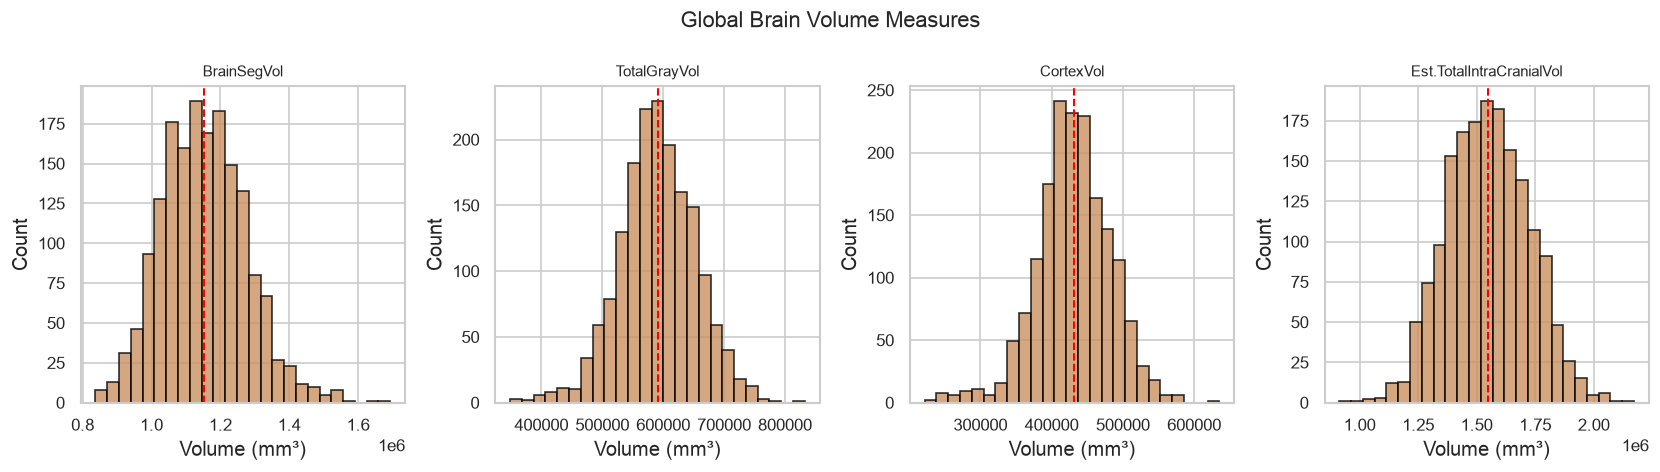

In [8]:
global_cols = ['BrainSegVol','TotalGrayVol','CortexVol','EstimatedTotalIntraCranialVol']
global_cols = [c for c in global_cols if c in aseg.columns]

fig, axes = plt.subplots(1, len(global_cols), figsize=(14, 4))
for ax, col in zip(axes, global_cols):
    data = aseg[col].dropna()
    data.hist(bins=25, ax=ax, color=sns.color_palette('colorblind')[5],
              edgecolor='black', alpha=0.8)
    ax.axvline(data.mean(), color='red', linestyle='--', linewidth=1.2)
    ax.set_title(col.replace('Estimated','Est.'), fontsize=9)
    ax.set_xlabel('Volume (mm³)'); ax.set_ylabel('Count')
plt.suptitle('Global Brain Volume Measures', fontsize=13)
plt.tight_layout(); plt.show()

## 6 · Subcortical Volume Correlations

Are the two hemispheres correlated? Are caudate and putamen correlated with each other?

In [9]:
if len(pd_structs) >= 4:
    short = {c: c.replace('Left-','L-').replace('Right-','R-').replace('Hippocampus','Hipp') for c in pd_structs}
    corr = aseg[pd_structs].rename(columns=short).corr()
    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1,
                ax=ax, linewidths=0.5)
    ax.set_title('Subcortical Volume Correlations')
    plt.tight_layout(); plt.show()

## Key Takeaways

- **Putamen and caudate** are the most PD-relevant subcortical structures — atrophy here is a key PD biomarker
- **High L/R symmetry** at the group level; individual asymmetry may be clinically meaningful
- **eTIV normalisation** is essential when comparing volumes across people of different head sizes
- **~1,700 participants** have FreeSurfer data — a large enough sample for group comparisons
- These morphometric measures complement DaTSCAN: anatomy vs. function